# 08 - Fit-quality control that works at low counts

The expectation of `deviance_per_dof` depends on how bright the plasma is (notebook
05), so a fixed threshold on it flags brightness, not misfits. This notebook computes
two statistics whose expectation does not depend on the count level, for the 30
example epochs, and shows how to turn them into flags for a long run.

**Runtime:** about half a minute.

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 1. Two statistics

**Randomized PIT and KS test.** For a Poisson pixel with expected counts $\mu$ and
observed counts $C$, the randomized probability integral transform

$$ u = F(C - 1 \mid \mu) + U \,[F(C \mid \mu) - F(C - 1 \mid \mu)], \qquad U \sim \mathcal{U}(0, 1), $$

($F$ = Poisson CDF) is uniform when the model is right, at any count level, zeros
included. A Kolmogorov-Smirnov test of all the $u$ against the uniform distribution
gives one p-value per epoch, and one for the strahl wedge alone. The uniform draws are
seeded by the epoch time, so the numbers are reproducible.

**Calibrated deviance.** Under the Poisson model the deviance of a pixel has an exact
expectation $\mathrm{E}[D \mid \mu]$ and variance. Summed over the grid:
$R = \sum D / \sum \mathrm{E}[D]$ and $z = (\sum D - \sum \mathrm{E}[D]) / \sqrt{\sum \mathrm{Var}[D]}$.
Poisson noise alone gives $R = 1$, $z \approx 0$.

(R is the ratio: the deviance we actually got, divided by the deviance we should get from Poisson noise alone. z is the same difference, but expressed in standard deviations. It tells us how significant the excess is. i.e., R says how big the misfit is, z says how sure we are it's real, and both work at any count level.)

Code: `evdf_poisson/qc.py`. `qcEpoch` handles one epoch, `qcFile` every row of a runner
CSV, and `python -m evdf_poisson.qc --data-dir <dir> --run-dir <results>` a whole run
(writes `<results>/qc/`).

{'ks_stat': 0.0098, 'ks_p': 0.0004, 'd_red': 0.5458, 'dev_ratio': 1.1402, 'dev_z': 14.6402, 'ks_stat_wedge': 0.0719, 'ks_p_wedge': 0.0, 'dev_ratio_wedge': 1.5256, 'dev_z_wedge': 12.4552}


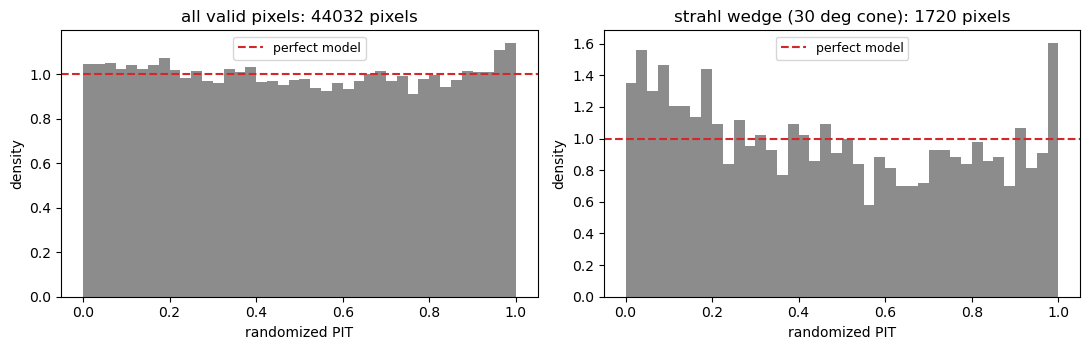

In [2]:
import json
from evdf_poisson.qc import qcEpoch, qcFile, flagQcTable

EPOCH = 20
summary = pd.read_csv(RESULTS_DIR / 'summary.csv')
row = summary.set_index('epoch_index').loc[EPOCH]
result = qcEpoch(EXAMPLE_FILE, EPOCH, json.loads(row['fit_params_json']), strahlSign=int(row['strahl_sign']))
print({key: round(value, 4) for key, value in result.items() if isinstance(value, float)})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, values, title in ((axes[0], result['pit_values'], 'all valid pixels'),
                          (axes[1], result['pit_values_wedge'], 'strahl wedge (30 deg cone)')):
    ax.hist(values, bins=40, range=(0, 1), color='0.55', density=True)
    ax.axhline(1, color='#d62728', linestyle='--', label='perfect model')
    ax.set_xlabel('randomized PIT'); ax.set_ylabel('density'); ax.set_title(f'{title}: {len(values)} pixels'); ax.legend(fontsize=9)
fig.tight_layout()

Reading the PIT histogram:

- **flat:** the counts are consistent with the model;
- **surplus near 0:** fewer counts than predicted (model too high there); **near 1:**
  the opposite;
- **U shape:** the data scatter more than the model allows (over-dispersion); a
  **hump:** less.

## 2. The 30 epochs

In [3]:
qcTable = flagQcTable(qcFile(EXAMPLE_FILE, summary, workers=4))
qcTable[['epoch_index', 'n_pixels', 'n_detected', 'ks_p', 'd_red', 'dev_ratio', 'dev_z',
         'ks_p_wedge', 'dev_ratio_wedge', 'flag_hard', 'flag_strong', 'flag_wedge']].round(4)

,epoch_index,n_pixels,n_detected,ks_p,d_red,dev_ratio,dev_z,ks_p_wedge,dev_ratio_wedge,flag_hard,flag_strong,flag_wedge
0,0,44032,12856,0.0001,0.5393,1.1371,14.1369,0.0000,1.3980,False,True,True
1,1,44032,12957,0.0000,0.5823,1.2107,21.8502,0.0000,1.4412,False,True,True
2,2,44032,13196,0.0000,0.5703,1.1727,18.0282,0.0000,1.4172,False,True,True
3,3,44032,13046,0.0000,0.5734,1.1816,18.9028,0.0010,1.2723,False,True,True
4,4,44032,13083,0.0000,0.6050,1.2320,24.2864,0.0000,1.7920,False,True,True
5,5,44032,13034,0.0000,0.5635,1.1695,17.6547,0.0039,1.3279,False,True,False
6,6,44032,13086,0.0000,0.6024,1.2277,24.0009,0.0004,1.5997,False,True,True
7,7,44032,13238,0.0000,0.5860,1.2030,21.3605,0.0007,1.2192,False,True,True
8,8,44032,13142,0.0000,0.6263,1.2657,28.2956,0.0000,1.7367,False,True,True
9,9,44032,12585,0.0010,0.5479,1.1542,15.9986,0.0000,1.3961,False,False,True


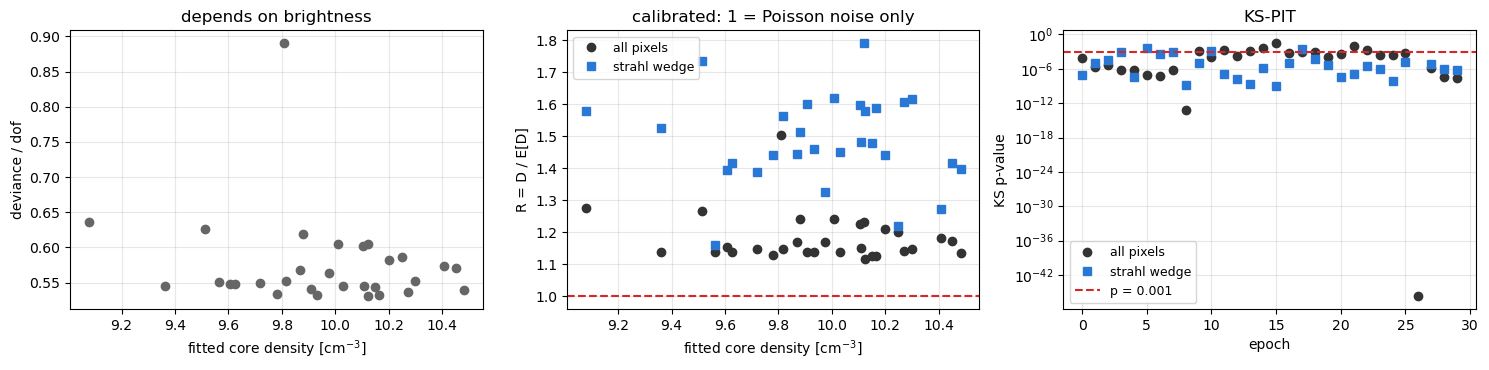

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(summary['n_c'], qcTable['d_red'], 'o', color='0.4')
axes[0].set_xlabel('fitted core density [cm$^{-3}$]'); axes[0].set_ylabel('deviance / dof'); axes[0].set_title('depends on brightness')
axes[1].plot(summary['n_c'], qcTable['dev_ratio'], 'o', color='0.2', label='all pixels')
axes[1].plot(summary['n_c'], qcTable['dev_ratio_wedge'], 's', color='#2a78d6', label='strahl wedge')
axes[1].axhline(1, color='#d62728', linestyle='--'); axes[1].set_xlabel('fitted core density [cm$^{-3}$]')
axes[1].set_ylabel('R = D / E[D]'); axes[1].set_title('calibrated: 1 = Poisson noise only'); axes[1].legend(fontsize=9)
axes[2].semilogy(qcTable['epoch_index'], np.maximum(qcTable['ks_p'], 1e-300), 'o', color='0.2', label='all pixels')
axes[2].semilogy(qcTable['epoch_index'], np.maximum(qcTable['ks_p_wedge'], 1e-300), 's', color='#2a78d6', label='strahl wedge')
axes[2].axhline(1e-3, color='#d62728', linestyle='--', label='p = 0.001'); axes[2].set_xlabel('epoch'); axes[2].set_ylabel('KS p-value')
axes[2].set_title('KS-PIT'); axes[2].legend(fontsize=9)
for ax in axes: ax.grid(alpha=0.3)
fig.tight_layout()

## 3. From statistics to flags

The rules used on month-long runs at 1 au (January 2022, 30 000 epochs):

| flag | rule | meaning |
|---|---|---|
| hard | detected pixels $\le 1000$ | too few counts: information-poor, not a misfit |
| strong | KS $p < 10^{-3}$ **and** $R > 1.1$ | large and significant misfit over the whole grid |
| wedge | KS $p_\text{wedge} < 10^{-3}$ | misfit inside the strahl cone (matters for strahl science only) |
| soft | KS $p < 10^{-3}$ but $R \le 1.1$ | significant but small; recorded, not excluded |

On that month 0.8 % of the epochs were *strong* and 1.3 % *wedge*. On the 30 example
epochs the strong rule fires on most and the wedge rule on nearly all. The reason is
the count level: at 0.33 au the grid holds 44 000 valid pixels with up to ~15 counts at
the peak, so the tests resolve the limits of the model itself, not fluctuations. A
single truncated bi-kappa cannot reproduce both the shoulder and the tail of the
strahl; the wedge $R$ of 1.3-1.8 says exactly that.

Two consequences:

- Thresholds transfer between data sets only where the model is adequate at that count
  level. Calibrate the flags on the run's own distribution of $R$ (for example median
  plus three robust standard deviations) and treat $R$ as a *ranking* of epochs.
- Keep the wedge statistics separate from the whole-grid ones, and use them only when
  the science is about the strahl.

In [5]:
ratio = qcTable['dev_ratio']
robustSigma = 1.4826 * np.median(np.abs(ratio - ratio.median()))
threshold = ratio.median() + 3 * robustSigma
outliers = qcTable.loc[ratio > threshold, ['epoch_index', 'dev_ratio', 'dev_ratio_wedge', 'ks_p']]
print(f'R: median {ratio.median():.3f}, robust sigma {robustSigma:.3f}, run-relative threshold {threshold:.3f}')
print(f'epochs above the run-relative threshold: {len(outliers)} of {len(qcTable)}')
outliers.round(4)

R: median 1.151, robust sigma 0.029, run-relative threshold 1.239
epochs above the run-relative threshold: 5 of 30


,epoch_index,dev_ratio,dev_ratio_wedge,ks_p
8,8,1.2657,1.7367,0.0
26,26,1.5033,NaN,0.0
27,27,1.2416,1.5129,0.0
28,28,1.2427,1.6200,0.0
29,29,1.2765,1.5810,0.0


## Summary

- The randomized PIT + KS test and the calibrated deviance ($R$, $z$) are valid at any
  count level; `deviance_per_dof` is not comparable across brightness.
- Run them on a whole result directory with
  `python -m evdf_poisson.qc --data-dir <dir> --run-dir <results>`.
- Flags need calibrating on each data set: a statistically significant misfit is not
  necessarily a bad fit when the counts are high enough to resolve the model's own
  limits.